# 05 — Zodi and exozodi

Two diffuse backgrounds share the planet's aperture: our own zodiacal light, and the target's
exozodiacal dust. Both are pure shot noise in this model (no residual structure), and both are
counted over the resel and multiplied by the mask throughput.

In this notebook:
1. how the two backgrounds are parameterized,
2. "zodis" and surface brightness,
3. an exozodi sweep: when does the dust matter?

In [1]:
import warnings
import numpy as np
import astropy.units as u
import matplotlib.pyplot as plt
import esc_etc
from esc_etc import Simulation, use_lazuli_style

use_lazuli_style()
warnings.filterwarnings("ignore", module="synphot")

sim = Simulation.from_default(filter="R3", hoststarmag=4.83, hoststar_band="johnson_v",
                              planetdeltamag=20, contrast=1e-8, ppgain=10, separation=0.4)

def frame_for(sim, max_frame=1000 * u.s):
    """Frame time to use: max_frame, or half the saturation time if that is shorter."""
    return min(u.Quantity(max_frame, u.s), 0.5 * sim.saturation_time())


def hours_to_snr(sim, snr=5, max_frame=1000 * u.s):
    """Integration time (hours) to reach snr with the current configuration; NaN above the speckle plateau."""
    return sim.get_int_time_for_snr(snr, frame_for(sim, max_frame))["int_time_continuous"][0].to_value(u.hr)

***
## 1. Parameterization

- `bg_flux` (default 22.5): local zodi surface brightness in **V mag/arcsec²**.
- `exobg_flux` (default 21): exozodi as a **delta magnitude per arcsec² relative to the host**, in
  the ESC band. So `scene.exozodi.mag` is `hoststarmag + 21`.

Both elements take an absolute surface brightness through `update`, in any band.

In [2]:
ex = sim.scene.exozodi
print(f"exozodi: mag = {ex.mag:.2f} mag/arcsec² (= host 4.83 + 21), band = {ex.band} (None = ESC band)")
print(f"zodi:    mag = {sim.scene.zodi.mag} mag/arcsec² in {sim.scene.zodi.band}")
r = sim.count_rate_components()
print(f"rates at 0.4\" [e-/s]: planet {r.source:.3g}, speckle {r.speckle:.3g}, zodi {r.zodi:.3g}, exozodi {r.exozodi:.3g}")
print(f"aperture {sim.sensor.aperture_solid_angle:.5f}, mask throughput {sim.coronagraph.off_axis_throughput():.2f}")

exozodi: mag = 25.83 mag/arcsec² (= host 4.83 + 21), band = None (None = ESC band)
zodi:    mag = 22.5 mag/arcsec² in johnson_v
rates at 0.4" [e-/s]: planet 0.0837 electron / s, speckle 0.0837 electron / s, zodi 0.00341 electron / s, exozodi 9.54e-05 electron / s
aperture 0.00161 arcsec2, mask throughput 0.57


***
## 2. Zodis

A common convention (EXOSIMS, Stark et al. 2014): **1 zodi = 22 V mag/arcsec² at 1 AU from a
solar-luminosity star**, falling as $r^{-2}$, face on. At projected separation $r = \theta d$:

$$\mu_V(n) = 22 - 2.5\log_{10} n + 5\log_{10}(r / \mathrm{AU}).$$

In [3]:
D_PC, SEP = 10.0, 0.4
r_AU = SEP * D_PC

def sb_zodis(n, r_au=r_AU):
    return 22.0 - 2.5 * np.log10(n) + 5 * np.log10(r_au)

print(f"r = {r_AU:.0f} AU: 1 zodi = {sb_zodis(1):.2f} V mag/arcsec², 10 zodi = {sb_zodis(10):.2f}, 100 zodi = {sb_zodis(100):.2f}")
print(f"the default exobg_flux = 21 corresponds to {10 ** (-0.4 * (4.83 + 21 - sb_zodis(1))):.2f} zodi here (ignoring the V vs R3 colour)")

r = 4 AU: 1 zodi = 25.01 V mag/arcsec², 10 zodi = 22.51, 100 zodi = 20.01
the default exobg_flux = 21 corresponds to 0.47 zodi here (ignoring the V vs R3 colour)


***
## 3. When does the dust matter?

> ✏️ **Before you run the next cell:** at how many zodis does the time to S/N 5 double for this planet: 10, 100 or 1000? Write your guess down (or put it in the room poll), then run.

no exozodi: 0.40 h; 10 zodi: x1.01; 100 zodi: x1.11; doubles at 888 zodi


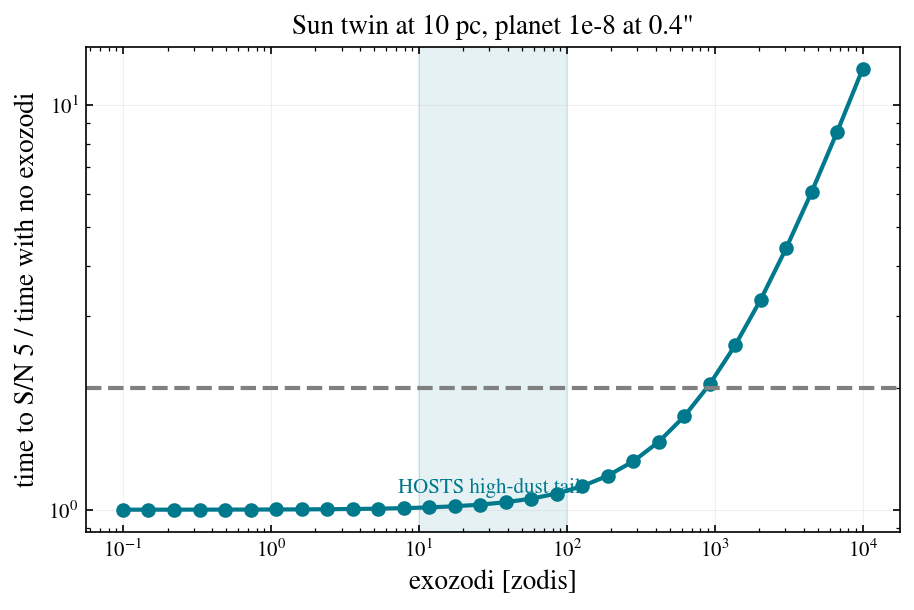

In [4]:
zodis = np.geomspace(0.1, 1e4, 30)

def hours_at(n_zodi):
    sim.update(scene__exozodi__mag=99.0 if n_zodi == 0 else sb_zodis(n_zodi), scene__exozodi__band="johnson_v")
    h = hours_to_snr(sim)
    sim.reset()
    return h

t0 = hours_at(0)
ratio = np.array([hours_at(n) for n in zodis]) / t0
n_double = np.interp(2.0, ratio, zodis)
print(f"no exozodi: {t0:.2f} h; 10 zodi: x{np.interp(10, zodis, ratio):.2f}; 100 zodi: x{np.interp(100, zodis, ratio):.2f}; doubles at {n_double:.0f} zodi")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.loglog(zodis, ratio, "o-")
ax.axhline(2, color="0.5", ls="--"); ax.axvspan(10, 100, color="C0", alpha=0.1)
ax.text(30, 1.1, "HOSTS high-dust tail", ha="center", color="C0")
ax.set(xlabel="exozodi [zodis]", ylabel="time to S/N 5 / time with no exozodi", title="Sun twin at 10 pc, planet 1e-8 at 0.4\"")
plt.show()

The doubling happens where the exozodi rate equals the planet plus all other background rates. At
0.4" from a Sun twin the resel is tiny and the dust has to be very bright to compete with the
speckle photons. That changes in the habitable zone of a nearby star, where $r$ is small and the
$r^{-2}$ law makes each zodi much brighter (exercise 5).

> 🤖 **Ask Jupyter AI:** *Repeat the sweep for the habitable zone of tau Ceti (3.65 pc, 0.7 AU, V = 3.5) with a 1e-10 Earth-like contrast and ppgain 100. Does the planet clear the floor at all, and if so, at how many zodis does its time double?*
>
> If the answer is NaN everywhere, ask it what raw contrast would be needed.

***
## Summary

```python
Simulation.from_default(bg_flux=22.5, exobg_flux=21)                         # zodi (V mag/arcsec²), exozodi (delta mag vs host)
sim.update(scene__exozodi__mag=mu_V, scene__exozodi__band="johnson_v")      # absolute surface brightness
mu_V(n zodi) = 22 - 2.5 log10(n) + 5 log10(r / AU)
```

Now pick an exercise: [README](README.md).